# Lab 3 — Millions of TVs, Who Is Watching?
Name: Kuksa Zahar | Group: KM-43

## Setup

In [1]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

In [2]:
START, END = pd.Timestamp('2024-10-14'), pd.Timestamp('2024-10-28')
DAYS = pd.date_range(START, END - pd.Timedelta(days=1))
BIG = ['CBS', 'NBC', 'ABC', 'FOX', 'FNC']
TEN = BIG + ['FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST']
def eastern_naive(s):
    s = pd.to_datetime(s)
    return s.dt.tz_convert('America/New_York').dt.tz_localize(None) if s.dt.tz is not None else s
for df in [programs, viewings]:
    for col in ['start_ts', 'end_ts']:
        df[col] = eastern_naive(df[col])
raw = acr_sessions.copy()
for old, new in [('start_utc', 'start_ts'), ('end_utc', 'end_ts')]:
    raw[new] = pd.to_datetime(raw[old], utc=True).dt.tz_convert('America/New_York').dt.tz_localize(None)
raw['minutes'] = (raw['end_ts'] - raw['start_ts']).dt.total_seconds() / 60
assert raw['session_id'].is_unique and (raw['minutes'] > 0).all()
edited = raw[raw['minutes'] >= 1].copy()

def split_days(df):
    # Clip to the study window and split sessions at 06:00 Eastern.
    x = df[(df['end_ts'] > START + pd.Timedelta(hours=6)) &
           (df['start_ts'] < END + pd.Timedelta(hours=6))].copy()
    x['start_ts'] = x['start_ts'].clip(lower=START + pd.Timedelta(hours=6))
    x['end_ts'] = x['end_ts'].clip(upper=END + pd.Timedelta(hours=6))
    x['bdate'] = (x['start_ts'] - pd.Timedelta(hours=6)).dt.normalize()
    pieces = []
    while len(x):
        boundary = x['bdate'] + pd.Timedelta(days=1,hours=6)
        stop = x['end_ts'].where(x['end_ts'] <= boundary, boundary)
        part = x.copy()
        part['hours'] = (stop - part['start_ts']).dt.total_seconds() / 3600
        pieces.append(part)
        x = x[x['end_ts'] > boundary].copy()
        x['start_ts'] = boundary.loc[x.index]
        x['bdate'] += pd.Timedelta(days=1)
    return pd.concat(pieces, ignore_index=True)
rs = split_days(raw)
a = split_days(edited)
in_tab = a.groupby('bdate')['tv_id'].nunique().reindex(DAYS, fill_value=0)
daily_weights['broadcast_date'] = pd.to_datetime(daily_weights['broadcast_date']).dt.tz_localize(None)
dw = daily_weights[daily_weights['broadcast_date'].between(START, DAYS[-1])].copy()
hdw = dw[dw['resp_type'] == 'H'].copy()
hw = hdw.groupby('respondent_id')['weight'].mean()
plt.rcParams.update({'figure.figsize': (10,4), 'axes.grid': True, 'grid.alpha': 0.2})

## Task 1.1 — Five questions
**Answer:**

| Source | Grain | Key | Coverage | Weight | Provenance |
|---|---|---|---|---|---|
| acr_sessions | One continuous session on one TV | session_id; tv_id identifies a set | Opted-in smart TVs, Oct 14–27; live/DVR networks, app and unknown activity | None; each TV counts once | Synthetic OEM-style ACR feed; screen fingerprints compared with a reference library |
| Lab 1 viewings | One respondent's continuous network-viewing session | viewing_id; respondent_id identifies the household/person | In-tab panel households and R/L persons; ten networks in October | Daily respondent projection weight | Synthetic representative metered panel |

Coverage is the biggest difference: the ACR footprint is a self-selected sample of sets, whereas the panel represents households and people. The lack of projection weights in ACR makes that coverage difference directly affect its estimates. Neither file is an actual census of US viewing.

## Task 1.2 — Size and shape

In [3]:
print("TVs:", raw['tv_id'].nunique())
print("Sessions:", len(raw))
print("Broadcast days:", a['bdate'].nunique())
print("Average TVs in-tab per day:", round(in_tab.mean(), 1))
# Use the after-edit in-tab definition for both denominators.
print("Hours per TV per day, raw:", f"{rs['hours'].sum() / in_tab.sum():.2f}")
print("Hours per TV per day, after edit rule:", f"{a['hours'].sum() / in_tab.sum():.2f}")
print("Share of sessions dropped:", round(1 - len(edited) / len(raw), 3))

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29090.1
Hours per TV per day, raw: 4.73
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299


## Task 1.3 — What the TV could not see

In [4]:
for col in ['session_type', 'input_source']:
    print('\nShare of hours by', col)
    print((a.groupby(col)['hours'].sum() / a['hours'].sum()).to_string(float_format=lambda x: f'{x:.3f}'))
unknown_share = a.loc[a['session_type'] == 'unknown', 'hours'].sum() / a['hours'].sum()
print("Share of TV-on hours unknown (%):", round(unknown_share * 100, 1))


Share of hours by session_type
session_type
app       0.257
dvr       0.025
live      0.322
unknown   0.396

Share of hours by input_source
input_source
antenna            0.086
built_in_app       0.307
cable_box          0.276
game_or_disc       0.024
satellite_box      0.076
streaming_device   0.231
Share of TV-on hours unknown (%): 39.6


**Answer:** A real feed can have a less complete fingerprint library, more local or niche channels, and more screens that cannot be matched reliably. Games/discs and unrecognized streaming or HDMI content can both become unknown. A reference library may also miss time-shifted or altered content. App use can be detected without recognizing the program inside the app; here app sessions have their own category, so they must not be added to identified network hours. The handout's real-feed unknown share (66%) describes another sample and period, not a correction factor for this one.

## Task 2.1 — Match

In [5]:
ip_counts = hh_attributes.dropna(subset=['hashed_ip']).groupby('hashed_ip')['household_id'].nunique()
tv_ip = raw[['tv_id', 'hashed_ip']].drop_duplicates()
assert not tv_ip['tv_id'].duplicated().any(), 'A TV has changing IPs: resolve linkage first.'
tv_ip['n_households'] = tv_ip['hashed_ip'].map(ip_counts).fillna(0).astype(int)
print("Matched to one household (%):", round(tv_ip['n_households'].eq(1).mean() * 100, 1))
print("Shared IP, unresolved (%):", round(tv_ip['n_households'].gt(1).mean() * 100, 1))
print("Not matched (%):", round(tv_ip['n_households'].eq(0).mean() * 100, 1))
unique_hh = hh_attributes[hh_attributes['hashed_ip'].map(ip_counts).eq(1)].drop_duplicates('hashed_ip')
matched = tv_ip[tv_ip['n_households'].eq(1)].merge(unique_hh, on='hashed_ip', validate='many_to_one')

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** An IP is an address of a connection, not a permanent household ID. Apartment buildings or carrier networks can share one address, and addresses can change or be reassigned. Hashing preserves these collisions and changes; it does not turn the address into a reliable identity. Keeping only unique matches avoids duplicating TVs but can add match-selection bias.

## Task 2.2 — Profile

In [6]:
region_map = {841:'Northeast', 842:'Midwest', 843:'South', 844:'West'}
income_map = {811:'Under $50k',812:'Under $50k',813:'$50–100k',814:'$50–100k',815:'$100k+',816:'$100k+'}
income_groups = {'Under $25k':'Under $50k','$25k-$50k':'Under $50k',
                 '$50k-$75k':'$50–100k','$75k-$100k':'$50–100k',
                 '$100k-$150k':'$100k+','$150k+':'$100k+'}
panel_profile = hw.rename('weight').to_frame()
for col, mapping in [('region',region_map),('income_group',income_map)]:
    attrs = viewer_attributes[viewer_attributes['attr_id'].isin(mapping)].copy()
    assert not attrs['respondent_id'].duplicated().any()
    panel_profile[col] = panel_profile.index.map(attrs.set_index('respondent_id')['attr_id'].map(mapping))
matched['income_group'] = matched['income_band'].map(income_groups)
assert panel_profile[['region','income_group']].notna().all().all()
assert matched['income_group'].notna().all()
profiles = {}
for col in ['region','income_group']:
    footprint = matched[col].value_counts(normalize=True)
    panel = panel_profile.groupby(col)['weight'].sum() / hw.sum()
    t = pd.DataFrame({'footprint_share':footprint,'panel_share':panel})
    t['index'] = t['footprint_share'] / t['panel_share'] * 100
    profiles[col] = t
    print('\n' + col)
    print(t.to_string(formatters={'footprint_share':'{:.3f}'.format,'panel_share':'{:.3f}'.format,'index':'{:.1f}'.format}))
print('\nHead age among matched TVs (share):')
print(matched['head_age_band'].value_counts(normalize=True).sort_index().to_string(float_format=lambda x:f'{x:.3f}'))


region
          footprint_share panel_share index
region                                     
Midwest             0.201       0.210  96.0
Northeast           0.150       0.170  88.0
South               0.383       0.379 101.0
West                0.266       0.241 110.4

income_group
             footprint_share panel_share index
income_group                                  
$100k+                 0.421       0.350 120.1
$50–100k               0.320       0.289 110.8
Under $50k             0.259       0.361  71.8

Head age among matched TVs (share):
head_age_band
18-34   0.196
35-49   0.348
50-64   0.263
65+     0.192


**Answer:** The matched footprint over-represents South, West and under-represents Midwest, Northeast. For income, $100k+, $50–100k are over-represented and Under $50k are under-represented (100 is parity). Buying a compatible connected TV and opting into tracking are related to income, age, internet access and geography, so more TVs do not automatically produce a representative sample. This profile describes unique IP matches only; unmatched homes could have a different profile.

## Task 2.3 — Ratings

In [7]:
def watchers(sessions, telecast, id_col):
    x = sessions[(sessions['network_code'] == telecast.network_code) &
                 (sessions['start_ts'] < telecast.end_ts) & (sessions['end_ts'] > telecast.start_ts)]
    overlap = (x['end_ts'].clip(upper=telecast.end_ts) -
               x['start_ts'].clip(lower=telecast.start_ts)).dt.total_seconds()
    return x.loc[overlap >= 60, id_col].unique()

refs = reference_ratings.merge(programs, on='telecast_id', validate='one_to_one')
refs['bdate'] = (refs['start_ts'] - pd.Timedelta(hours=6)).dt.normalize()
live = edited[edited['session_type'] == 'live']
ratings = refs.set_index('telecast_id')[['program_name','episode_name','network_code','bdate','hh_rating']].copy()
ratings = ratings.rename(columns={'hh_rating':'reference_hh_rating'})
ratings['n_in_tab'] = ratings['bdate'].map(in_tab)
ratings['tvs_watched'] = [len(watchers(live,r,'tv_id')) for r in refs.itertuples()]
ratings['tv_hh_rating'] = ratings['tvs_watched'] / ratings['n_in_tab'] * 100
ratings['ratio'] = ratings['tv_hh_rating'] / ratings['reference_hh_rating']
ratings['gap_pp'] = ratings['tv_hh_rating'] - ratings['reference_hh_rating']
print(ratings[['program_name','network_code','tv_hh_rating','reference_hh_rating','ratio','gap_pp']]
      .to_string(formatters={c:'{:.1f}'.format for c in ['tv_hh_rating','reference_hh_rating','gap_pp']} | {'ratio':'{:.3f}'.format}))

                                     program_name network_code tv_hh_rating reference_hh_rating ratio gap_pp
telecast_id                                                                                                 
1013636                            MLB Postseason          FOX         16.5                25.9 0.639   -9.3
1021823                              NFL Football          NBC         21.2                33.1 0.641  -11.9
1004042                                      NCIS          CBS          5.4                10.6 0.509   -5.2
1012442                                   Hannity          FNC          0.8                 2.3 0.359   -1.5
1016852                         Unsellable Houses         HGTV          2.1                 3.7 0.568   -1.6
1013031             Halloween Baking Championship         FOOD          1.0                 1.6 0.604   -0.6
1014236                              Grotesquerie           FX          2.3                 3.5 0.641   -1.3
1003476      The Re

**Answer:** MLB Postseason, NFL Football, NCIS, Hannity, Unsellable Houses, Halloween Baking Championship, Grotesquerie, The Real Housewives of New York City are below the reference; none are above it. By proportional distance from the reference, Hannity is furthest off (ratio 0.359) and NFL Football is closest (0.641). The table also gives absolute gaps in rating points, which need not have the same ranking. A younger, more affluent footprint would particularly miss older-skewing CBS/Fox News audiences relative to FX/Bravo. Income and region alone cannot prove that explanation; the head-age profile is supporting context. Capturing only one set per home can depress ratings across programs independently of demographic skew.

## Task 3.1 — Hours per home

In [8]:
al = a[(a['session_type'] == 'live') & a['network_code'].isin(TEN)].copy()
hv = viewings[(viewings['resp_type'] == 'H') & viewings['network_code'].isin(TEN) &
              viewings['playback'].str.lower().eq('live')].copy()
hv = split_days(hv).drop(columns='weight')
hv = hv.merge(hdw[['respondent_id','broadcast_date','weight']],
              left_on=['respondent_id','bdate'],right_on=['respondent_id','broadcast_date'],validate='many_to_one')
hv['weighted_hours'] = hv['hours'] * hv['weight']
tv_hours = al['hours'].sum() / in_tab.sum()
panel_hours = hv['weighted_hours'].sum() / hdw['weight'].sum()
print("Live hours per TV per day (ten networks):", round(tv_hours, 2))
print("Live hours per panel household per day (ten networks):", round(panel_hours, 2))
print("Difference (panel minus TVs, hours):", round(panel_hours - tv_hours, 2))

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92
Difference (panel minus TVs, hours): 1.05


**Answer:** The TVs record 0.87 hours per in-tab TV-day, compared with 1.92 weighted hours per panel household-day, a difference of 1.05 hours. A single observed set misses viewing on other sets, while household panel records cover the home. The lecture's averages (about 2.6 sets per home, about 1.1 of the same brand) explain why one OEM feed is incomplete, but multiplying hours by 2.6 would not be a valid correction: set use differs and simultaneous viewing/reach overlap matters. Footprint selection and day-level data loss also affect this comparison.

## Task 3.2 — Network shares

In [9]:
network_shares = pd.DataFrame({
    'share_in_tvs':al.groupby('network_code')['hours'].sum() / al['hours'].sum(),
    'share_in_panel':hv.groupby('network_code')['weighted_hours'].sum() / hv['weighted_hours'].sum()})
network_shares['difference_pp'] = (network_shares['share_in_tvs'] - network_shares['share_in_panel']) * 100
print(network_shares.sort_values('difference_pp').to_string(formatters={
    'share_in_tvs':'{:.3f}'.format,'share_in_panel':'{:.3f}'.format,'difference_pp':'{:.1f}'.format}))

             share_in_tvs share_in_panel difference_pp
network_code                                          
FNC                 0.085          0.110          -2.5
CBS                 0.182          0.196          -1.4
HIST                0.019          0.019           0.1
FOOD                0.024          0.022           0.2
BRAVO               0.016          0.013           0.3
HGTV                0.034          0.031           0.3
FX                  0.028          0.022           0.6
NBC                 0.214          0.206           0.7
FOX                 0.201          0.194           0.8
ABC                 0.196          0.187           0.9


**Answer:** Relative to the weighted panel's ten-network mix, smart TVs overstate ABC, BRAVO, FOOD, FOX, FX, HGTV, HIST, NBC and understate CBS, FNC. These are shares of live hours on these ten networks, not shares of all TV-on time or ratings.

## Task 3.3 — What each can see
**Answer:** The panel identifies the people watching, including their age/sex and co-viewing, links household viewing across sets, and uses in-tab weights to project to US households and people. ACR alone cannot tell which household members are watching or cover other/untracked sets and opted-out homes.

The ACR file logs activity on many networks outside the ten-network panel extract, distinguishes app use and unknown TV-on time, and records input sources such as consoles and streaming devices. This does not mean it identifies the program inside every app, or that the panel measurement system itself can never measure those things: the comparison is with the provided files.

## Task 4.1 — Daily plots

            tvs_in_tab all_hours hours_per_in_tab_tv big5_hours_per_in_tab_tv
2024-10-14       29940 134957.29                4.51                     0.81
2024-10-15       29940 133517.89                4.46                     0.65
2024-10-16       29940 133188.89                4.45                     0.57
2024-10-17       29940 131919.51                4.41                     0.59
2024-10-18       29940 131485.00                4.39                     0.69
2024-10-19       29940 158878.80                5.31                     0.98
2024-10-20       29940 159138.18                5.32                     1.00
2024-10-21       29940 136469.84                4.56                     0.78
2024-10-22       18041  79361.93                4.40                     0.64
2024-10-23       29940 132928.52                4.44                     0.57
2024-10-24       29940 132526.87                4.43                     0.59
2024-10-25       29940 132082.12                4.41            

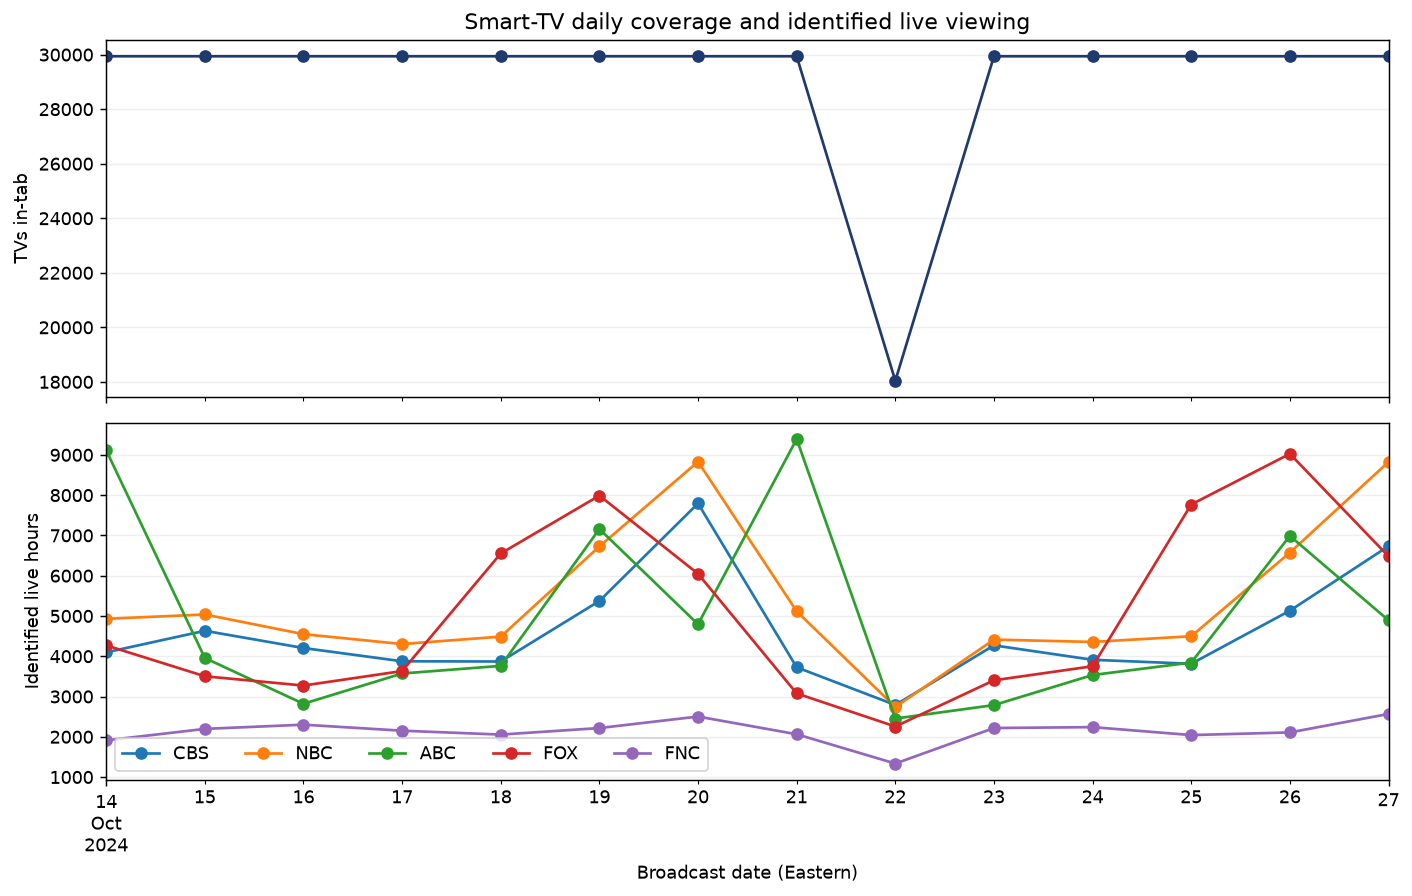

In [10]:
big_daily = al[al['network_code'].isin(BIG)].groupby(['bdate','network_code'])['hours'].sum().unstack(fill_value=0).reindex(DAYS)
daily = pd.DataFrame({'tvs_in_tab':in_tab,'all_hours':a.groupby('bdate')['hours'].sum()})
daily['hours_per_in_tab_tv'] = daily['all_hours'] / daily['tvs_in_tab']
daily['big5_hours_per_in_tab_tv'] = big_daily.sum(axis=1) / in_tab
fig, ax = plt.subplots(2,1,figsize=(11,7),sharex=True)
ax[0].plot(DAYS,in_tab,marker='o',color='#1f3a6e')
ax[0].set_ylabel('TVs in-tab'); ax[0].set_title('Smart-TV daily coverage and identified live viewing')
big_daily[BIG].plot(ax=ax[1],marker='o')
ax[1].set_ylabel('Identified live hours'); ax[1].set_xlabel('Broadcast date (Eastern)')
ax[1].legend(ncol=5); fig.tight_layout(); plt.show()
print(daily.to_string(formatters={c:'{:.2f}'.format for c in daily.columns if c!='tvs_in_tab'}))

## Task 4.2 — Spike and broken day

In [11]:
spike_date, spike_net = big_daily.stack().idxmax()
broken = in_tab.idxmin()
print("Biggest spike (date, network):", (spike_date.strftime('%Y-%m-%d'), spike_net))
print("Broken day (date):", broken.strftime('%Y-%m-%d'))
# Attribute the spike to actual scheduled telecasts, using overlap hours.
spike_programs = programs[(programs['network_code']==spike_net) &
                         ((programs['start_ts']-pd.Timedelta(hours=6)).dt.normalize()==spike_date)].copy()
sx = live[(live['network_code']==spike_net) &
          (live['start_ts']<spike_date+pd.Timedelta(days=1,hours=6)) &
          (live['end_ts']>spike_date+pd.Timedelta(hours=6))]
def overlap_hours(r):
    x = sx[(sx['start_ts']<r.end_ts)&(sx['end_ts']>r.start_ts)]
    return ((x['end_ts'].clip(upper=r.end_ts)-x['start_ts'].clip(lower=r.start_ts)).dt.total_seconds()/3600).sum()
spike_programs['observed_live_hours'] = [overlap_hours(r) for r in spike_programs.itertuples()]
print(spike_programs[['program_name','episode_name','observed_live_hours']].sort_values('observed_live_hours',ascending=False).head(5).to_string(index=False,float_format=lambda x:f'{x:.2f}'))
print("In-tab coverage vs other-day median (share):", round(in_tab.loc[broken]/in_tab.drop(broken).median(),3))
print("Hours per TV vs other-day median (share):", round(daily.loc[broken,'hours_per_in_tab_tv']/daily.drop(broken)['hours_per_in_tab_tv'].median(),3))

Biggest spike (date, network): ('2024-10-21', 'ABC')
Broken day (date): 2024-10-22
                  program_name                              episode_name  observed_live_hours
                  NFL Football                    NFL Football: BAL @ TB              6991.21
Local / Syndicated Programming                                       NaN               419.78
          Good Morning America Alessia Cara, Jenny Slate, Dr. Jill Biden               291.04
Local / Syndicated Programming                                       NaN               247.05
Local / Syndicated Programming                                       NaN               242.33
In-tab coverage vs other-day median (share): 0.603
Hours per TV vs other-day median (share): 0.986


**Answer:** The biggest network-day is ABC on 2024-10-21; its largest scheduled contributor is **NFL Football — NFL Football: BAL @ TB**. That is an event-driven viewing spike. On 2024-10-22, the in-tab count falls to 18,041, while the diagnostic table shows how hours per remaining TV compare with surrounding days. A broad denominator/coverage collapse points to missing reporting rather than simply an unpopular program. Missing TVs depress daily totals; ratings can remain superficially plausible if numerator and denominator fall together, or become biased if missingness is selective. Flag the day and exclude it from unqualified planning estimates until the vendor explains and backfills it. Do not invent missing viewing or automatically scale every rating; preserve the day in the required raw comparison and show any exclusion as a separate sensitivity check.

## Task 5.1 — Sampling error vs bias

In [12]:
selected = ratings[ratings['program_name'].str.contains('NFL Football|Hannity|Unsellable Houses',case=False)].copy()
assert len(selected)==3
selected['n_panel'] = selected['bdate'].map(hdw.groupby('broadcast_date')['respondent_id'].nunique())
p = selected['reference_hh_rating'] / 100
selected['se_footprint'] = np.sqrt(p * (1-p) / selected['n_in_tab']) * 100
selected['se_panel'] = np.sqrt(p * (1-p) / selected['n_panel']) * 100
selected['se_reduction_factor'] = selected['se_panel'] / selected['se_footprint']
selected['abs_gap_in_se'] = selected['gap_pp'].abs()/selected['se_footprint']
print(selected[['program_name','n_in_tab','n_panel','se_footprint','se_panel','se_reduction_factor','gap_pp','abs_gap_in_se']]
      .to_string(formatters={c:'{:.3f}'.format for c in ['se_footprint','se_panel','se_reduction_factor','abs_gap_in_se']} | {'gap_pp':'{:.1f}'.format}))

                  program_name  n_in_tab  n_panel se_footprint se_panel se_reduction_factor gap_pp abs_gap_in_se
telecast_id                                                                                                     
1021823           NFL Football     29940     3898        0.272    0.754               2.771  -11.9        43.710
1012442                Hannity     29940     3867        0.087    0.241               2.783   -1.5        17.026
1016852      Unsellable Houses     29940     3867        0.109    0.303               2.783   -1.6        14.617


**Answer:** The footprint's nominal SE is about 2.8 times smaller than the panel's for all three telecasts (about a 64% reduction). Its absolute gaps from the reference are about 11.9 points for Sunday Night Football, 1.5 for Hannity and 1.6 for Unsellable Houses: approximately 44, 17 and 15 footprint SEs respectively. The observed discrepancy is much larger than sampling error. It reflects coverage and selection problems, whereas the binomial formula describes hypothetical random-sample uncertainty. More observations reduce that sampling term as 1/√n, but do not recover unobserved sets or people, represent opted-out homes, or repair demographic skew. These are illustrative simple-random-sample SEs; the weighted panel and convenience footprint do not literally satisfy that model, so the comparison does not certify either estimate's total error.

## Task 5.2 — Answer to the planner

**Answer:** Today I can report an unweighted observed-TV household-rating proxy of **21.2%** for Dallas at San Francisco on NBC on October 27: TVs with at least one qualifying live session divided by that day's in-tab TVs. The reference household rating is **33.1%**, so the feed differs by **-11.9 rating points**. Its nominal sampling SE is only **0.272 points**, but that precision does not remove the larger coverage and selection problems. The feed does not identify people or co-viewers, misses other sets and homes that opted out, and does not identify the programs inside app/unknown activity. IP-unmatched homes still count in this overall TV proxy, but we cannot reliably assign their household demographics. Before using it for planning, I would require audited coverage and linkage, investigation/backfill of the broken day, representative calibration and validation against panel/currency ratings. I would label today's number as a device-footprint observation and use the validated currency for the client household claim.

## Bonus

In [13]:
sn_ref = refs[refs['program_name'].str.contains('NFL Football',case=False)].iloc[0]
sn_day = sn_ref['bdate']
dayw = dw[dw['broadcast_date']==sn_day]
age = pd.to_numeric(viewer_attributes[viewer_attributes['attr_id']==300].set_index('respondent_id')['value'],errors='coerce')
targetw = dayw[dayw['resp_type'].isin(['R','L']) & dayw['respondent_id'].map(age).between(25,54)]
housew = dayw[dayw['resp_type']=='H']
pv = viewings[viewings['playback'].str.lower().eq('live')]
hh_seen = watchers(pv[pv['resp_type']=='H'], sn_ref, 'respondent_id')
person_seen = watchers(pv[pv['resp_type'].isin(['R','L'])],sn_ref,'respondent_id')
hh_audience = housew.loc[housew['respondent_id'].isin(hh_seen),'weight'].sum()
target_audience = targetw.loc[targetw['respondent_id'].isin(person_seen),'weight'].sum()
vpvh = target_audience / hh_audience
hh_universe, target_universe = housew['weight'].sum(), targetw['weight'].sum()
sn_tv_rating = ratings.loc[sn_ref['telecast_id'],'tv_hh_rating']
target_rating = sn_tv_rating * vpvh * hh_universe / target_universe
print("VPVH A25-54:", round(vpvh,3))
print("A25-54 rating (persons):", round(target_rating,1))
print("US TV households (day's weights):", int(hh_universe))
print("US A25-54 persons (day's weights):", int(target_universe))

VPVH A25-54: 0.513
A25-54 rating (persons): 11.1
US TV households (day's weights): 125800789
US A25-54 persons (day's weights): 123738777


**Answer:** This assumes footprint viewing homes have the same A25–54 viewers per viewing household as the weighted panel for this specific telecast, despite the footprint's demographic and set-coverage differences. It also treats the single-set household proxy as transferable to whole homes, and uses the same-day panel universes. The conversion does not observe people on the smart TVs and inherits the original household-rating bias; it is an estimate under assumptions, not a measured A25–54 currency rating.